# 10 – Training diagnostics: overfitting, underfitting, convergence

Reads the **raw training logs** (`logs/<run>/history.csv`) of every trained model and
1. builds an evidence table per model (best epoch, plateau, sustained decline, gap between training loss and validation),
2. checks the logs for anomalous values (NaN, spikes),
3. plots training loss, validation mIoU / OA and the learning rate per model,
4. combines train / validation / test scores (after running `evaluate.py --split train` and `--split val`).

**Decision rules (stated in advance, so the diagnosis is not subjective):**
* *Sustained validation decline*: mean validation mIoU of the last 5 epochs is more than 0.02 below the best value
  **and** the slope over the last 10 epochs is below −0.001 per epoch → **overfitting confirmed by validation**.
* *Plateau*: last-10-epoch slope between −0.001 and +0.001 and last-5 mean within 0.02 of the best → **converged**.
  If the training loss still falls by > 5 % after the best epoch → the **generalisation gap is widening**
  (*possible* mild overfitting; confirm with training mIoU in eval mode).
* *Still improving*: best epoch among the last 3 epochs run and positive slope → **possibly under-trained**.
* *Underfitting* can only be confirmed with a training metric in eval mode (cell 4): low training mIoU close to validation mIoU.

In [1]:
import glob, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJ = "/home/jovyan/vault/heidelberg_lulc_2025"
FIG = f"{PROJ}/outputs/figures/diagnostics"
EV = f"{PROJ}/outputs/evaluation"
os.makedirs(FIG, exist_ok=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

ARCH = {"segformer": "SegFormer", "unet": "U-Net", "deeplabv3plus": "DeepLabV3+", "fpn": "FPN"}
hist = {}
for p in sorted(glob.glob(f"{PROJ}/logs/*/history.csv")):
    run = os.path.basename(os.path.dirname(p))
    if not run.startswith("smoke_"):
        hist[run] = pd.read_csv(p)
print("runs:", list(hist))


def slope(v):
    v = np.asarray(v, dtype=float)
    return float(np.polyfit(np.arange(len(v)), v, 1)[0]) if len(v) >= 3 else np.nan


rows = []
for run, h in hist.items():
    arch, tr = run.split("_train")[0], run.split("_train")[1].split("_")[0]
    val_cols = [c for c in h.columns if c.startswith("val") and c.endswith("_miou")]
    for vc in val_cols:
        res = vc[3:-5]
        v = h[vc].values
        b = int(np.nanargmax(h["select_score"].values))           # checkpoint epoch (selection score)
        best, last5, sl10 = v[b], np.nanmean(v[-5:]), slope(v[-10:])
        tl = h["train_loss"].values
        tl_drop_after_best = (tl[b] - tl[-1]) / tl[b] if b < len(tl) - 1 else 0.0
        if last5 < best - 0.02 and sl10 < -0.001:
            dx = "OVERFITTING (sustained validation decline)"
        elif b >= len(v) - 3 and sl10 > 0.001:
            dx = "still improving – possibly under-trained"
        elif abs(sl10) <= 0.001 or last5 >= best - 0.02:
            dx = ("plateau / converged; gap widening (train loss still falling)" if tl_drop_after_best > 0.05
                  else "plateau / converged")
        else:
            dx = "unclear – inspect curve"
        rows.append({"model": ARCH.get(arch, arch), "trained": f"{tr} m" if tr != "mix" else "mixed",
                     "val res": f"{res} m", "epochs": len(h), "best ep": int(h["epoch"].iloc[b]),
                     "best val mIoU": round(best, 4), "last-5 mean": round(last5, 4),
                     "slope last 10 (/ep)": round(sl10, 4),
                     "val OA best": round(h[f"val{res}_oa"].iloc[b], 4),
                     "train loss: first": round(tl[0], 3), "at best": round(tl[b], 3), "last": round(tl[-1], 3),
                     "loss drop after best": f"{100 * tl_drop_after_best:.1f} %",
                     "lr at best": f"{h['lr'].iloc[b]:.1e}" if "lr" in h else "–",
                     "diagnosis (rule-based)": dx})
diag = pd.DataFrame(rows).sort_values(["trained", "val res", "best val mIoU"], ascending=[True, True, False])
diag.to_csv(f"{FIG}/diagnosis_table.csv", index=False)
diag

runs: ['deeplabv3plus_train10_VV-VH-RATIO_s42', 'deeplabv3plus_train40_VV-VH-RATIO_s42', 'fpn_train10_VV-VH-RATIO_s42', 'fpn_train40_VV-VH-RATIO_s42', 'segformer_train10_VV-VH-RATIO_s42', 'segformer_train40_VV-VH-RATIO_s42', 'segformer_trainmix_VV-VH-RATIO_s42', 'unet_train10_VV-VH-RATIO_s42', 'unet_train40_VV-VH-RATIO_s42', 'unet_trainmix_VV-VH-RATIO_s42']


,model,trained,val res,epochs,best ep,best val mIoU,last-5 mean,slope last 10 (/ep),val OA best,train loss: first,at best,last,loss drop after best,lr at best,diagnosis (rule-based)
4,SegFormer,10 m,10 m,32,20,0.4495,0.4439,0.0008,0.8521,2.572,0.986,0.859,12.9 %,2.2e-04,plateau / converged; gap widening (train loss ...
0,DeepLabV3+,10 m,10 m,33,21,0.4378,0.4290,0.0003,0.8461,2.838,1.167,1.036,11.2 %,2.2e-04,plateau / converged; gap widening (train loss ...
8,U-Net,10 m,10 m,50,40,0.4377,0.4333,0.0001,0.8487,2.900,1.060,1.030,2.8 %,3.5e-05,plateau / converged
2,FPN,10 m,10 m,41,29,0.4262,0.4181,0.0009,0.8393,3.412,1.078,0.968,10.2 %,1.3e-04,plateau / converged; gap widening (train loss ...
9,U-Net,40 m,40 m,42,30,0.3756,0.3642,0.0005,0.8141,3.173,1.374,1.303,5.1 %,2.4e-04,plateau / converged; gap widening (train loss ...
5,SegFormer,40 m,40 m,31,19,0.3733,0.3660,0.0000,0.8068,3.422,1.299,1.189,8.5 %,2.8e-04,plateau / converged; gap widening (train loss ...
1,DeepLabV3+,40 m,40 m,60,48,0.3625,0.3539,-0.0001,0.7890,3.181,1.264,1.210,4.3 %,1.2e-04,plateau / converged
3,FPN,40 m,40 m,57,45,0.3529,0.3408,0.0003,0.7807,4.864,1.382,1.315,4.8 %,1.4e-04,plateau / converged
6,SegFormer,mixed,10 m,25,13,0.4437,0.4386,0.0014,0.8358,2.728,1.134,0.976,13.9 %,2.8e-04,plateau / converged; gap widening (train loss ...
10,U-Net,mixed,10 m,48,36,0.3652,0.3525,0.0003,0.7627,2.939,1.058,1.006,4.9 %,6.6e-05,plateau / converged


## 2. Raw-value checks: NaN / inf, spikes in the training loss
A *spike* is an epoch whose training loss is > 10 % above the previous epoch **and** above the median of its
neighbours (epochs 1–2 are excluded because the loss legitimately changes fast there).

In [2]:
for run, h in hist.items():
    tl = h["train_loss"].values
    bad = ~np.isfinite(h.select_dtypes("number").values)
    spikes = [(int(h["epoch"].iloc[i]), round(tl[i], 4), round(tl[i - 1], 4))
              for i in range(2, len(tl) - 1)
              if tl[i] > 1.10 * tl[i - 1] and tl[i] > 1.10 * np.median(tl[max(0, i - 2):i + 3])]
    print(f"{run:40s} NaN/inf values: {int(bad.sum()):3d} | loss spikes (epoch, value, previous): {spikes or 'none'}")

print("\nRaw training loss, U-Net trained at 40 m (to check the red point seen in the screenshot):")
u40 = [r for r in hist if r.startswith("unet_train40")]
if u40:
    print(hist[u40[0]][["epoch", "lr", "train_loss", "val40_miou", "val40_oa"]].round(4).to_string(index=False))

deeplabv3plus_train10_VV-VH-RATIO_s42    NaN/inf values:   0 | loss spikes (epoch, value, previous): none
deeplabv3plus_train40_VV-VH-RATIO_s42    NaN/inf values:   0 | loss spikes (epoch, value, previous): none
fpn_train10_VV-VH-RATIO_s42              NaN/inf values:   0 | loss spikes (epoch, value, previous): none
fpn_train40_VV-VH-RATIO_s42              NaN/inf values:   0 | loss spikes (epoch, value, previous): none
segformer_train10_VV-VH-RATIO_s42        NaN/inf values:   0 | loss spikes (epoch, value, previous): none
segformer_train40_VV-VH-RATIO_s42        NaN/inf values:   0 | loss spikes (epoch, value, previous): none
segformer_trainmix_VV-VH-RATIO_s42       NaN/inf values:   0 | loss spikes (epoch, value, previous): none
unet_train10_VV-VH-RATIO_s42             NaN/inf values:   0 | loss spikes (epoch, value, previous): none
unet_train40_VV-VH-RATIO_s42             NaN/inf values:   0 | loss spikes (epoch, value, previous): none
unet_trainmix_VV-VH-RATIO_s42            NaN/i

## 3. Per-model diagnostic plots (training loss, validation loss if logged, mIoU, OA, learning rate)

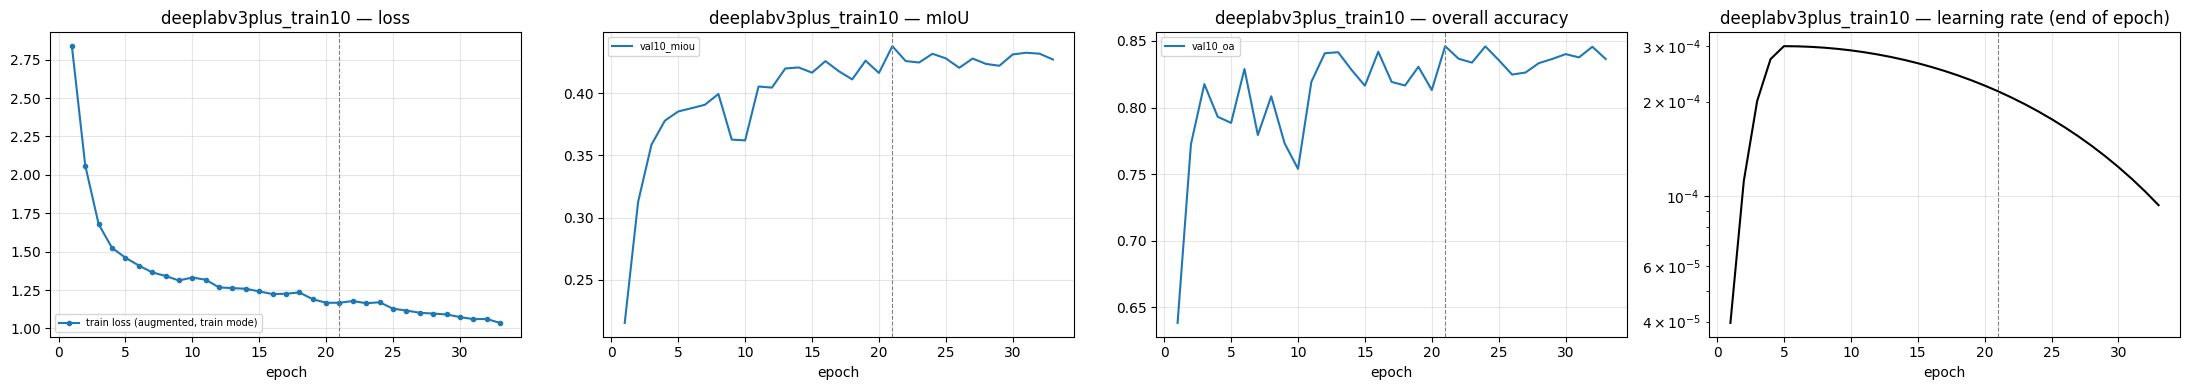

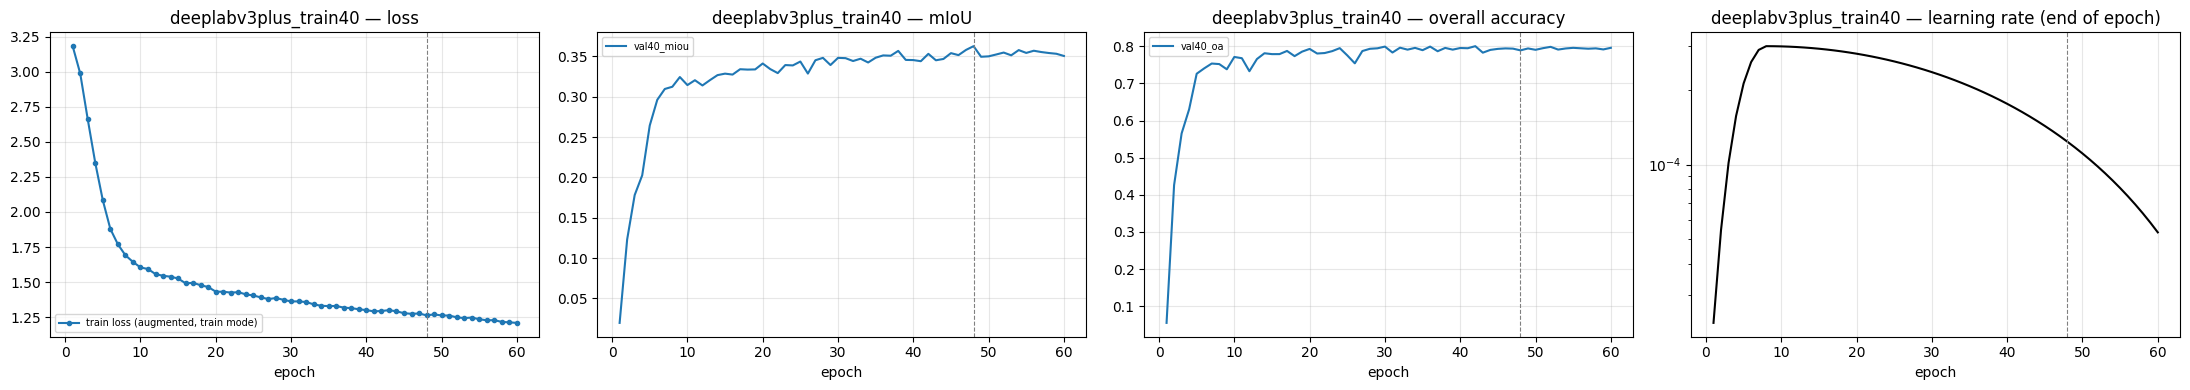

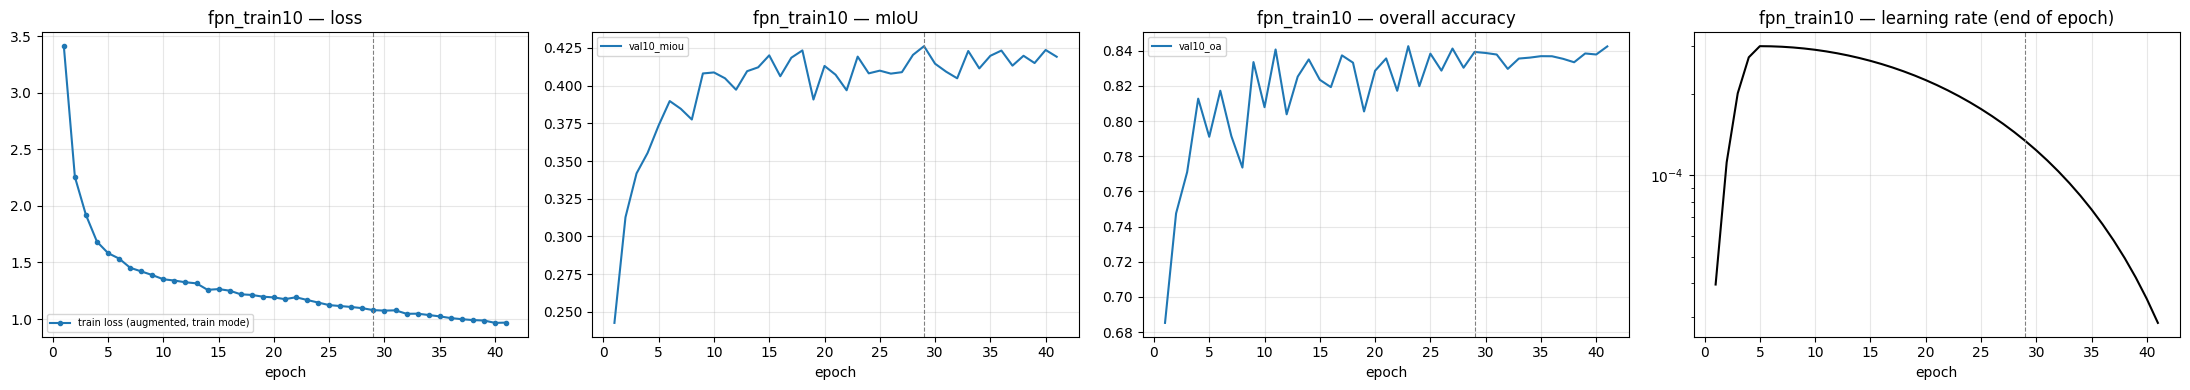

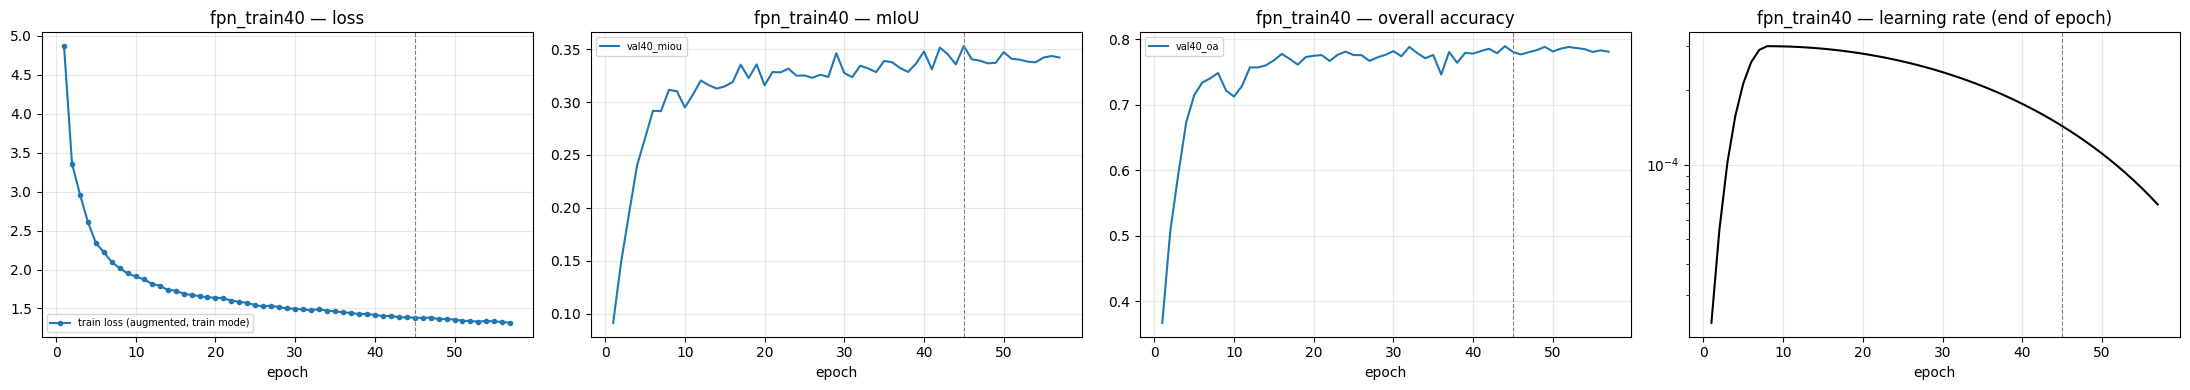

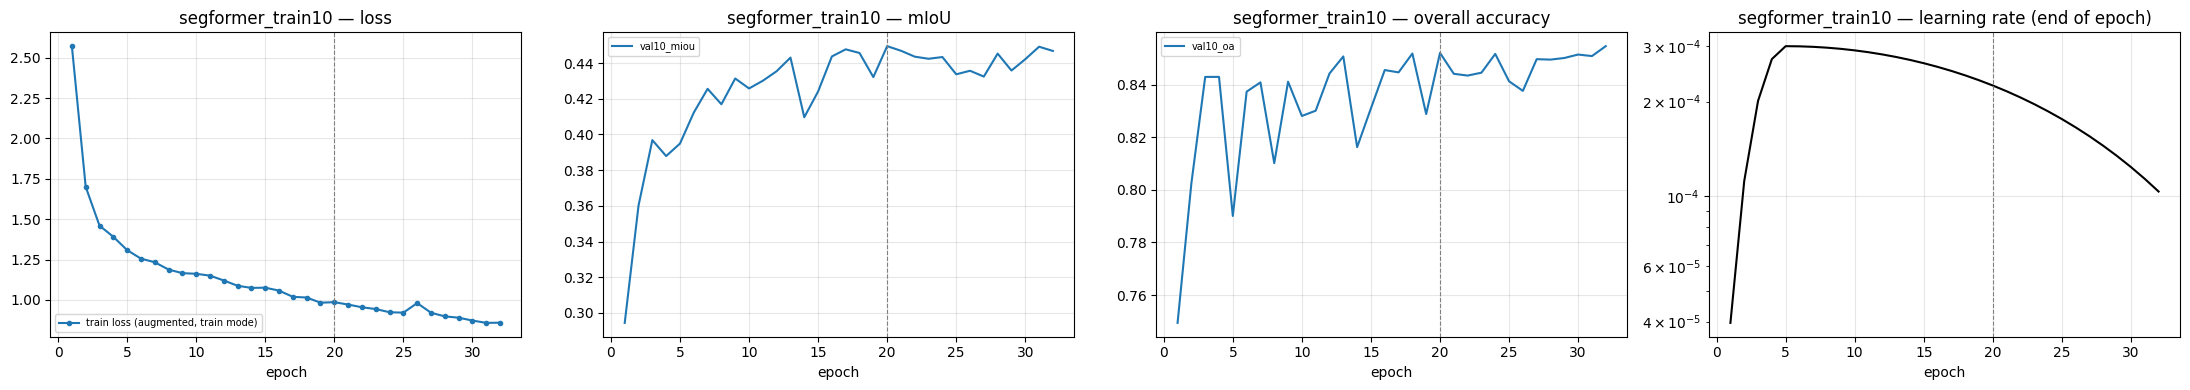

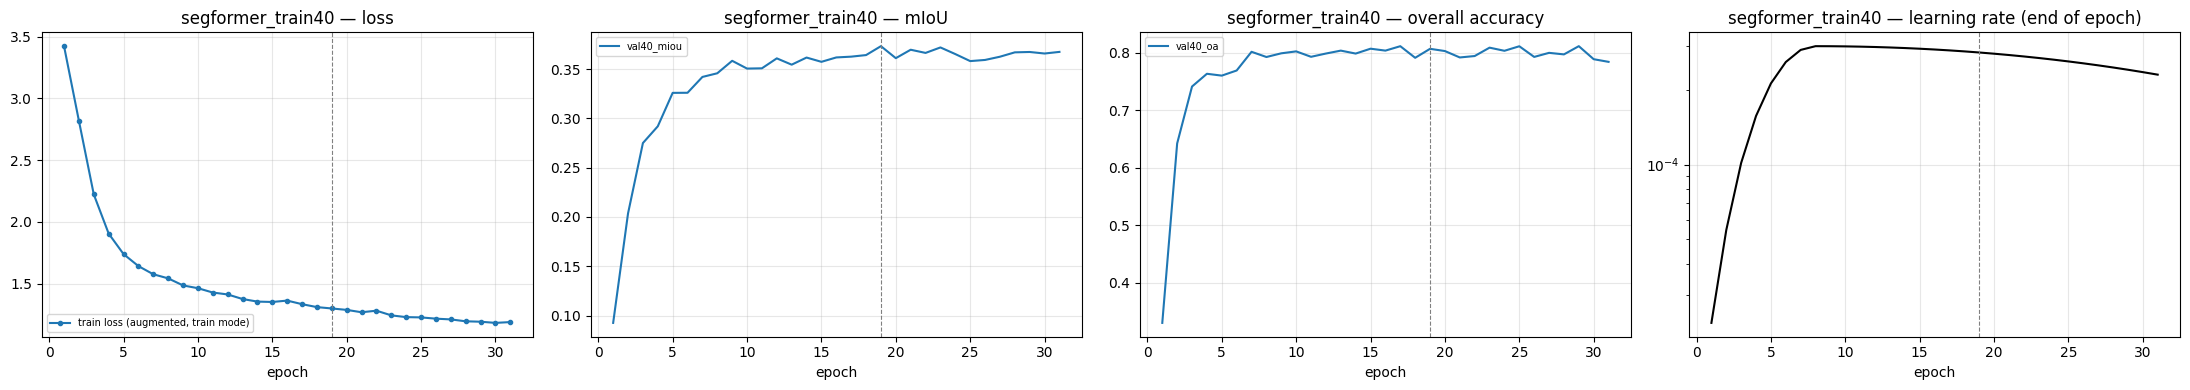

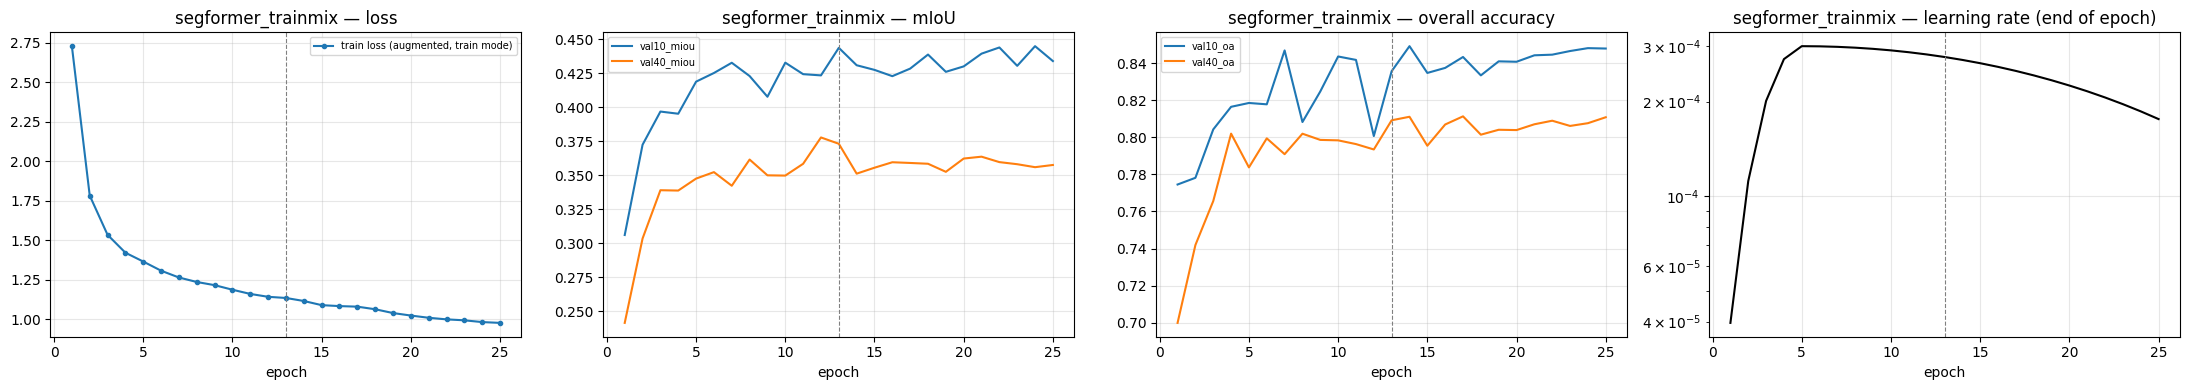

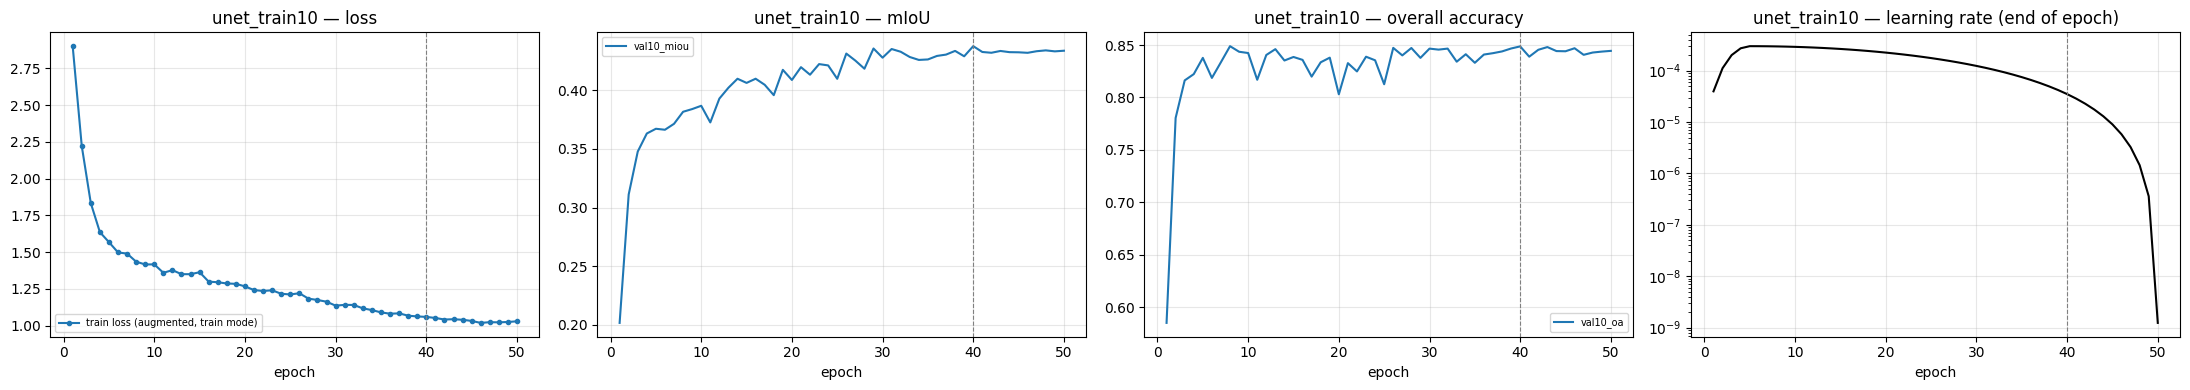

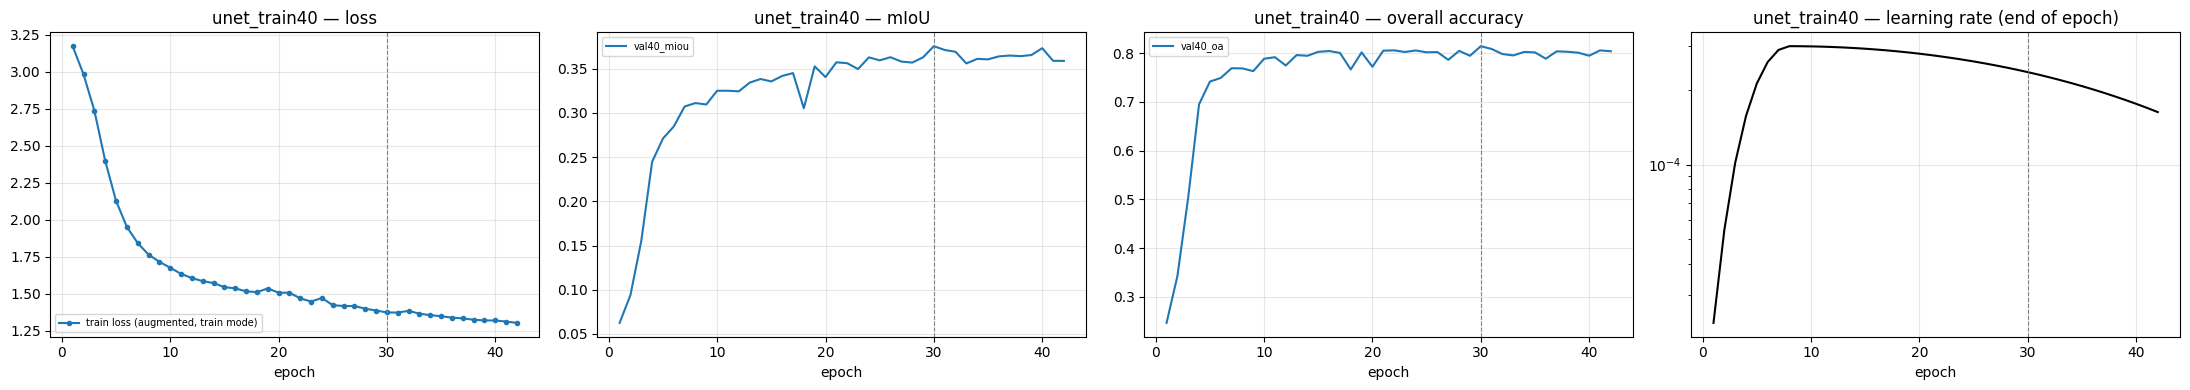

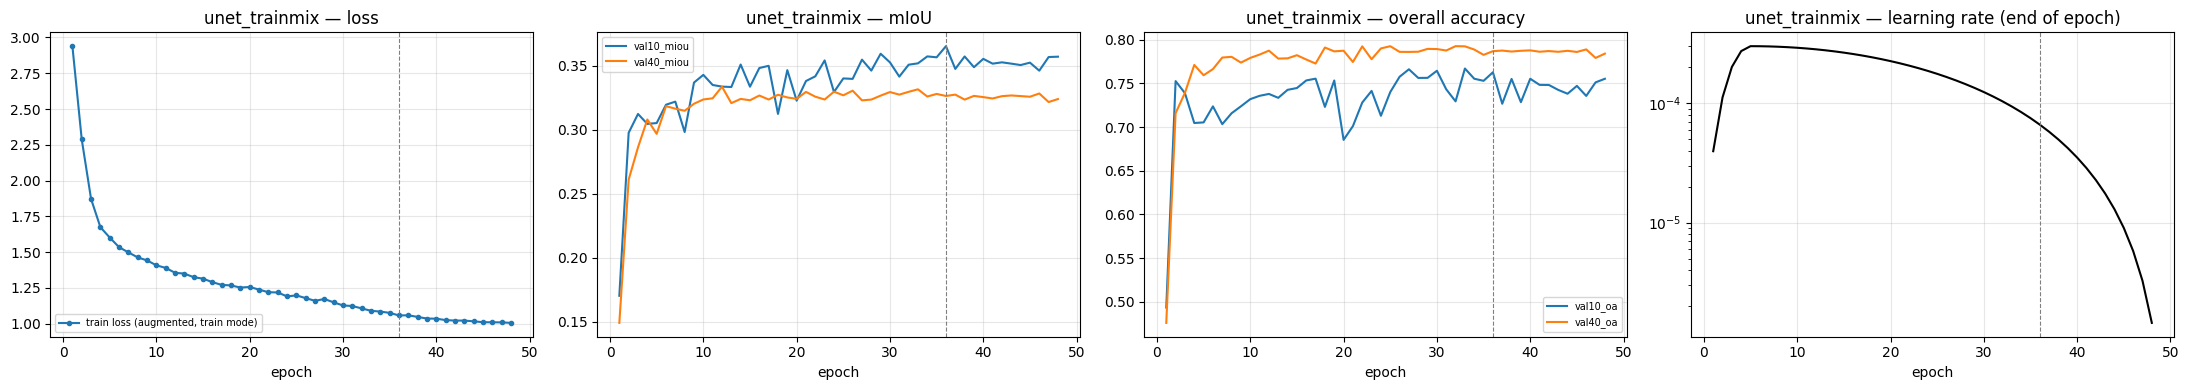

In [3]:
for run, h in hist.items():
    fig, axs = plt.subplots(1, 4, figsize=(22, 4))
    axs[0].plot(h.epoch, h.train_loss, "-o", ms=3, label="train loss (augmented, train mode)")
    for c in [c for c in h.columns if c.endswith("_loss") and c != "train_loss"]:
        axs[0].plot(h.epoch, h[c], "--", label=c)
    for c in [c for c in h.columns if c.endswith("_miou")]:
        axs[1].plot(h.epoch, h[c], "-" if c.startswith("val") else ":", label=c)
    for c in [c for c in h.columns if c.endswith("_oa")]:
        axs[2].plot(h.epoch, h[c], "-" if c.startswith("val") else ":", label=c)
    if "lr" in h:
        axs[3].plot(h.epoch, h.lr, color="k"); axs[3].set_yscale("log")
    b = h.select_score.idxmax()
    for ax, t in zip(axs, ["loss", "mIoU", "overall accuracy", "learning rate (end of epoch)"]):
        ax.axvline(h.epoch[b], color="grey", ls="--", lw=0.8)
        ax.set_title(f"{run.replace('_VV-VH-RATIO_s42', '')} — {t}"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
        if ax is not axs[3]:
            ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(f"{FIG}/{run}_diagnostics.png", dpi=110); plt.show()

## 4. Train / validation / test comparison (generalisation gap)
Requires (run once in a terminal; no retraining):
```
python3 scripts/evaluate.py --split train --gpu 0
python3 scripts/evaluate.py --split val   --gpu 0
```
*Training scores are computed on the full training split in eval mode without augmentation.*

In [5]:
parts = {}
for split, path in [("train", f"{EV}/train/summary_overall.csv"), ("val", f"{EV}/val/summary_overall.csv"),
                    ("test", f"{EV}/summary_overall.csv")]:
    if os.path.exists(path):
        parts[split] = pd.read_csv(path)
    else:
        print("missing:", path)

if parts:
    # one simple column per split and metric, e.g. "train_mIoU", "val_mIoU", "test_mIoU"
    frames = []
    for split, df in parts.items():
        d = df[["run", "mode", "OA", "mIoU", "mF1"]].copy()
        d = d.rename(columns={"OA": f"{split}_OA", "mIoU": f"{split}_mIoU", "mF1": f"{split}_mF1"})
        frames.append(d.set_index(["run", "mode"]))
    t = pd.concat(frames, axis=1).reset_index()

    # keep only matched resolution: 10 m models on 10 m data, 40 m models on 40 m data, mixed on both
    t["trained"] = t.run.str.split("_train").str[1].str.split("_").str[0]
    matched = ((t.trained == "10") & (t["mode"] == "test10")) | ((t.trained == "40") & (t["mode"] == "test40")) | \
              ((t.trained == "mix") & t["mode"].isin(["test10", "test40"]))
    t = t[matched].copy()
    t["model"] = t.run.str.split("_train").str[0].map(ARCH)
    t["data"] = t["mode"].map({"test10": "10 m", "test40": "40 m"})

    # generalisation gaps
    if {"train_mIoU", "test_mIoU"} <= set(t.columns):
        t["gap_train-test_mIoU"] = t["train_mIoU"] - t["test_mIoU"]
    if {"val_mIoU", "test_mIoU"} <= set(t.columns):
        t["gap_val-test_mIoU"] = t["val_mIoU"] - t["test_mIoU"]

    cols = [c for c in ["train_OA", "val_OA", "test_OA",
                        "train_mIoU", "val_mIoU", "test_mIoU",
                        "train_mF1", "val_mF1", "test_mF1",
                        "gap_train-test_mIoU", "gap_val-test_mIoU"] if c in t.columns]
    show = t.set_index(["trained", "model", "data"])[cols].round(3).sort_index()
    show.to_csv(f"{FIG}/train_val_test_table.csv")
    display(show)

train_OA  val_OA  test_OA  train_mIoU  val_mIoU  test_mIoU  train_mF1  val_mF1  test_mF1  gap_train-test_mIoU  gap_val-test_mIoU
trained model      data                                                                                                                                  
10      DeepLabV3+ 10 m     0.840   0.846    0.810       0.466     0.438      0.407      0.585    0.539     0.509                0.059              0.031
        FPN        10 m     0.850   0.839    0.816       0.509     0.426      0.400      0.636    0.523     0.496                0.109              0.026
        SegFormer  10 m     0.860   0.852    0.832       0.531     0.449      0.432      0.661    0.550     0.537                0.099              0.017
        U-Net      10 m     0.852   0.849    0.818       0.506     0.438      0.423      0.631    0.535     0.531                0.083              0.014
40      DeepLabV3+ 40 m     0.793   0.789    0.758       0.416     0.363      0.342      0.541    0.456     0.440                0.074              0.021
        FPN        40 m     0.798   0.781    0.758       0.428     0.353      0.327      0.560    0.447     0.420                0.102              0.026
        SegFormer  40 m     0.805   0.807    0.772       0.420     0.373      0.348      0.544    0.466     0.444                0.072              0.025
        U-Net      40 m     0.815   0.814    0.782       0.390     0.376      0.343      0.487    0.462     0.427                0.047              0.033
mix     SegFormer  10 m     0.837   0.836    0.811       0.496     0.444      0.422      0.623    0.545     0.528                0.074              0.022
                   40 m     0.820   0.809    0.787       0.455     0.373      0.357      0.588    0.467     0.454                0.099              0.017
        U-Net      10 m     0.760   0.763    0.718       0.395     0.365      0.334      0.513    0.457     0.432                0.061              0.032
                   40 m     0.800   0.787    0.749       0.392     0.326      0.295      0.505    0.399     0.372                0.097              0.032

## 5. Ranking of the architectures (matched resolution only)
Selection uses **validation** mIoU (the criterion used for checkpointing); test scores are reported, not used for choice.

In [6]:
if "test" in parts:
    sel = pd.DataFrame([{"run": r, "val_select": h.select_score.max()} for r, h in hist.items()])
    te = parts["test"]
    out = []
    for tr, mode in [("10", "test10"), ("40", "test40"), ("mix", "test10"), ("mix", "test40")]:
        sub = te[(te.run.str.contains(f"_train{tr}_")) & (te["mode"] == mode)].merge(sel, on="run")
        sub = sub.sort_values("val_select", ascending=False).assign(
            experiment=f"trained {tr} m → {mode[4:]} m test", rank_by_val=lambda d: range(1, len(d) + 1))
        out.append(sub[["experiment", "rank_by_val", "arch", "val_select", "OA", "mIoU", "mF1"]])
    rank = pd.concat(out).round(3)
    rank.to_csv(f"{FIG}/ranking.csv", index=False)
    display(rank)

,experiment,rank_by_val,arch,val_select,OA,mIoU,mF1
0,trained 10 m → 10 m test,1,segformer,0.450,0.832,0.432,0.537
1,trained 10 m → 10 m test,2,deeplabv3plus,0.438,0.810,0.407,0.509
2,trained 10 m → 10 m test,3,unet,0.438,0.818,0.423,0.531
3,trained 10 m → 10 m test,4,fpn,0.426,0.816,0.400,0.496
3,trained 40 m → 40 m test,1,unet,0.376,0.782,0.343,0.427
2,trained 40 m → 40 m test,2,segformer,0.373,0.772,0.348,0.444
0,trained 40 m → 40 m test,3,deeplabv3plus,0.363,0.758,0.342,0.440
1,trained 40 m → 40 m test,4,fpn,0.353,0.758,0.327,0.420
0,trained mix m → 10 m test,1,segformer,0.408,0.811,0.422,0.528
1,trained mix m → 10 m test,2,unet,0.346,0.718,0.334,0.432


In [7]:
pc_tr = pd.read_csv(f"{EV}/train/summary_per_class.csv")
pc_te = pd.read_csv(f"{EV}/summary_per_class.csv")
run = "segformer_train10_VV-VH-RATIO_s42"
a = pc_tr[(pc_tr.run == run) & (pc_tr["mode"] == "test10")].set_index("class")[["IoU", "F1"]]
b = pc_te[(pc_te.run == run) & (pc_te["mode"] == "test10")].set_index("class")[["IoU", "F1"]]
cmp = a.add_prefix("train_").join(b.add_prefix("test_"))
cmp["IoU_gap"] = cmp.train_IoU - cmp.test_IoU
cmp = cmp.round(3)
cmp.to_csv(f"{FIG}/segformer10_per_class_train_vs_test.csv")
display(cmp)

,train_IoU,train_F1,test_IoU,test_F1,IoU_gap
class,,,,,
Water,0.739,0.850,0.669,0.802,0.070
Trees,0.826,0.905,0.788,0.881,0.038
Grass,0.443,0.614,0.338,0.505,0.105
Flooded vegetation,0.362,0.531,0.041,0.080,0.320
Crops,0.769,0.870,0.730,0.844,0.040
Shrub and scrub,0.241,0.388,0.166,0.285,0.075
Built-up,0.832,0.908,0.844,0.915,-0.012
Bare ground,0.271,0.426,0.080,0.147,0.191
Snow and ice,0.292,0.453,0.233,0.377,0.060
